Install the following python packages using your package manager of choice (pip in this case)

In [26]:
!pip install numpy
!pip install scipy
!pip install pandas
!pip install f90nml
!pip install numba
!pip install plotly

Import the `m3dis` python package amongst other common packages

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import m3dis
plt.style.use('m3dis/Bergemann2020.mplstyle')
#plt.style.use('m3dis/Bergemann2023.mplstyle') # uncomment for serif axis labels
%config InlineBackend.figure_format='svg' # turns plots into vector graphics inside this notebook

Execute Multi by calling the Dispatch executable and supplying the default demo input parameter file `demo.nml`.
This will run a 1D solar Marcs model using a 6-Level toy Barium atom.

In [28]:
! ./dispatch.x demo.nml

OMP: Warning #182: OMP_STACKSIZE: ignored because KMP_STACKSIZE has been defined
 This version was compiled with default real KIND = 4
 MPI is not enabled!
 DISPATCH code framework, branch:nlte_patch, hash:b49198c41
 SOLVER=ramses/hlld_eos OPTS=
 Intel(R) Version 2021.11.1 Build 20231117_000000  
 ================================ mpi_t%info ====================================
 n_sockets =   1
   n_cores =  36
 n_threads =   1
  n_places =  36
   n_ranks =   1
 Stacksize =   256MB
 This version was compiled with default real KIND = 4
 ================================= io_t%init ====================================
 parameters from: demo.nml
 output directory: data/demo/
 ============================ read_external_t%ini ===============================
FeH was overwritten by Marcs model: [Fe/H] =  0.00
Vmic was overwritten by Marcs model: Vmic =  1.00
 Reading absmet file: input_multi3d/absmet
 ME I  deactivated!
  - Reading atom
  - Reading collision data
Changing abundance of Ba from  

The default output directory is `./data/`. A new subfolder is created according to the name of your input parameter file. It can be opened and read as follows:

In [29]:
run = m3dis.read('data/demo/')

Now we have created an object with the name of `run`. This object contains all of the data and meta-data of our demo run. The spectral data is contained in run.lam and run.flux. One can easily plot 
the spectrum using the `plot_spectrum()` function (which calls `plt.plot()` and all of its arguments):

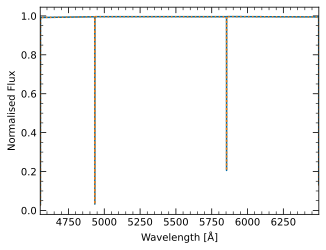

In [30]:
plt.plot(run.lam, run.flux/run.flux_cnt) # or alternatively
lam, flux = run.plot_spectrum(linestyle=':')

To zoom into a part of the spectrum one may do:

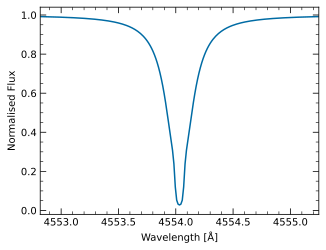

In [31]:
lam0 = 4554.033
dlam = 2.5
lam, flux = run.plot_spectrum(lam0=lam0, dlam=dlam)

`plot_spectrum()` trims the underlying spectral data using the  `crop()` function of the `run` object. The `crop()` function only returns the wavelengths and flux/intensity without plotting it. It has many useful arguments, which are also accepted by `plot_spectrum()`. Here I list the most important ones:
1. `lam0`, `dlam`: can be used in combination in order to crop the spectrum to a region around a central wavelength lam0. dlam may also be a tuple, e.g. (-0.5, 0.2), which would result in asymmetric cropping aroun lam0.
2. `xmin`,`xmax`: alternatively one may pass xmin and xmax instead to crop the wavelengths.
3. `lam_offset=False`: when one uses lam0 and dlam, the wavelength values are given as distance from lam0, but by setting lam_offset=False, one can keep the original wavelengths.
4. `norm=False`: plots the unnormalised spectrum.
5. `imu=0`: plots the disk-center intensity, rather than the flux. By increasing imu, you can plot the various angles of the chosen angle quadrature of the run.
6. `vdop=1.5`: applies doppler broadening with a velocity of 1.5 km/s by convolving with a Gaussian profile.
7. `vshift=1.5`: doppler shifts the spectrum corresponding to a velocity of 1.5 km/s.
8. `LTE=True`: plots the LTE spectrum. By default it will try to plot the NLTE spectrum.


An array accessible via `run.line` contains multiple objects of the `trans_class`. This class makes plotting of spectral lines stored in the model atom very easy. Each run stores both LTE and NLTE spectra by default. Let's make a quick comparison:

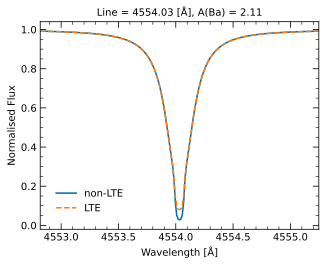

In [32]:
imu = None # None gives flux, use integers to plot intensities for different angles
norm = True # set to False for unnormalised line profile
kr = 0 # line index (note that python starts counting from 0)

line = run.line[kr]
line.plot(imu=imu, norm=norm, LTE=False, linestyle='-', label='non-LTE')
line.plot(imu=imu, norm=norm, LTE=True, linestyle='--', label='LTE')
plt.legend()

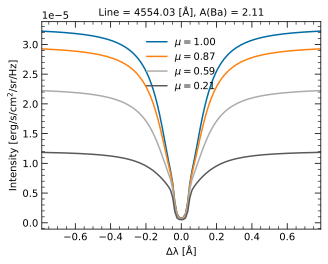

In [ ]:
dlam = 0.8 # zooms into the line profile to ±dlam angstroms.
norm = False

# alternatively one may get the line object by its wavelength
line = run.get_line(4554.033)

 # iterate over all angles
for imu, mu in enumerate(run.mus):
  label = r'$\mu=${:.2f}'.format(mu)
  line.plot(imu=imu, norm=norm, dlam=dlam, label=label)

plt.ylabel('Intensity [erg/s/cm$^2$/sr/Hz]')
plt.legend()

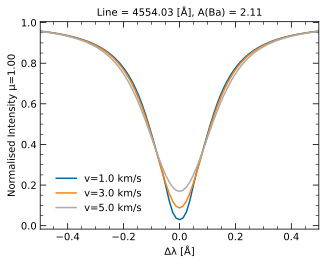

In [41]:
dlam = 0.5
imu = 0
line = run.get_line(4554.033)

 # convolve with doppler profiles
for vdop in [1.0, 3.0, 5.0]:
  label = 'v={:.1f} km/s'.format(vdop)
  line.plot(imu=imu, dlam=dlam, vdop=vdop, label=label)

plt.legend()

In [35]:
line = run.line[kr]
line.prepare()
data = {}
data['Wavelength'] = line.lam
data['Flux'] = line.flux / line.flux_cnt

# save angle resolved line profiles as ascii table
for imu, mu in enumerate(run.mus):
  label = '{:.3f}'.format(mu)
  data[label] = line.ie[:,imu] / line.cnt[:,imu]

df = pd.DataFrame(data=data)
ascii_table = df.to_string(index=False)
print(ascii_table)

 Wavelength     Flux    1.000    0.872    0.592    0.209
4552.817434 0.991931 0.992774 0.992322 0.991325 0.991602
4552.829580 0.991769 0.992629 0.992166 0.991150 0.991434
4552.841726 0.991601 0.992478 0.992006 0.990970 0.991260
4552.853873 0.991429 0.992323 0.991842 0.990785 0.991081
4552.866019 0.991250 0.992163 0.991672 0.990593 0.990897
4552.878165 0.991066 0.991998 0.991497 0.990395 0.990707
4552.890312 0.990877 0.991828 0.991317 0.990192 0.990511
4552.902459 0.990681 0.991652 0.991130 0.989981 0.990309
4552.914605 0.990480 0.991471 0.990938 0.989765 0.990100
4552.926752 0.990271 0.991283 0.990739 0.989541 0.989885
4552.938899 0.990055 0.991090 0.990533 0.989309 0.989662
4552.951046 0.989832 0.990890 0.990321 0.989069 0.989432
4552.963193 0.989602 0.990684 0.990101 0.988822 0.989194
4552.975340 0.989364 0.990471 0.989874 0.988566 0.988948
4552.987487 0.989118 0.990249 0.989639 0.988302 0.988694
4552.999634 0.988863 0.990020 0.989396 0.988028 0.988431
4553.011781 0.988598 0.989782 0